# NetSense-QoR — M7 generalisation on Kaggle

Tests how well the models work on **designs they have never seen** (PRD experiment 6, section 8.2).
3 variants (`m7_baseline`, `m7_ratio`, `m7_combined`) × 3 seeds × (1 random-split model + 4 held-out-design fold models)
= 45 training runs, plus few-shot fine-tuning, on 12 designs. Expect roughly **3 hours** on a GPU.

**Setup** (same as before): *Add Input* → your `openabc-mini` dataset; *Settings*: **Accelerator = GPU**, **Internet = on**.

**Run it as a saved version** so it keeps running when you close the tab and the outputs are kept:
*Save Version* → *Save & Run All (Commit)*. When it has finished, open the version and download the notebook
(*File* → *Download notebook*, or the ⋮ menu); the results table, per-run and per-design numbers and the bar chart are stored inside it.


In [1]:
!git clone https://github.com/tejaswini-18/netsense.git
%cd netsense
!git log --oneline -1

Cloning into 'netsense'...
remote: Enumerating objects: 171, done.
remote: Counting objects: 100% (171/171), done.
remote: Compressing objects: 100% (115/115), done.
remote: Total 171 (delta 87), reused 133 (delta 49), pack-reused 0 (from 0)
Receiving objects: 100% (171/171), 415.02 KiB | 10.92 MiB/s, done.
Resolving deltas: 100% (87/87), done.
/kaggle/working/netsense
75214df (HEAD -> main, origin/main, origin/HEAD) M7: generalisation runner (random / unseen designs / few-shot), 12-design configs, per-design graph batching


In [2]:
# Kaggle already has PyTorch (with GPU support), pandas, scipy, matplotlib, tqdm and pyyaml.
# Install only what is missing. Do NOT reinstall torch: that breaks the running session.
!pip install -q torch_geometric pytest
import torch, torch_geometric
print("torch", torch.__version__, "| PyG", torch_geometric.__version__, "| GPU:", torch.cuda.is_available())

torch 2.11.0+cu130 | PyG 2.8.1 | GPU: True


In [3]:
# Find the attached dataset (the folder that contains synthesisStatistics.pickle)
from pathlib import Path
DATA_ROOT = next(Path("/kaggle/input").rglob("synthesisStatistics.pickle")).parent
print("Dataset:", DATA_ROOT, "| design graphs:", len(list((DATA_ROOT / "graphs").glob("*.pt"))), "(expected 42)")

Dataset: /kaggle/input/datasets/tejaswinidharne18/openabc-mini | design graphs: 42 (expected 42)


In [4]:
# Quick check that everything works here before the long run
!NETSENSE_DATA_ROOT={DATA_ROOT} python -m pytest -q 2>&1 | tail -3


=========================== short test summary info ============================
FAILED tests/test_train.py::test_runner_builds_table_and_keeps_the_split_fixed_across_seeds
1 failed, 50 passed, 597 warnings in 32.74s


In [5]:
# All variants x seeds x settings. Progress bars are filtered out to keep the saved notebook small;
# each epoch line, each run's summary and a '>>>' line per finished setting are still printed.
!python -m src.run_generalisation --data-root {DATA_ROOT} --runs-dir /kaggle/working/runs --out /kaggle/working/results/generalisation 2>&1 | tr '\r' '\n' | grep -vE 'it/s\]|s/it\]|^ *$'


##### m7_baseline  seed 0  random split #####
Run folder: /kaggle/working/runs/m7_baseline_20261118_131611  |  device: cuda
Samples: {'train': 12600, 'val': 2700, 'test': 2700}
Model parameters: 35,938
epoch   1 train 0.9409 | val loss 0.8168 | MAPE_and 78.61%  tau_and 0.110 | MAPE_delay 232.30%  tau_delay -0.014 | 7s  *best*
epoch   2 train 0.6665 | val loss 0.5383 | MAPE_and 47.49%  tau_and 0.002 | MAPE_delay 209.82%  tau_delay -0.031 | 6s  *best*
epoch   3 train 0.4484 | val loss 0.3325 | MAPE_and 33.36%  tau_and 0.056 | MAPE_delay 172.62%  tau_delay -0.030 | 6s  *best*
epoch   4 train 0.2466 | val loss 0.1592 | MAPE_and 11.73%  tau_and 0.060 | MAPE_delay 106.68%  tau_delay -0.019 | 6s  *best*
epoch   5 train 0.1456 | val loss 0.1214 | MAPE_and 6.26%  tau_and 0.074 | MAPE_delay 96.64%  tau_delay -0.019 | 6s  *best*
epoch   6 train 0.1220 | val loss 0.1080 | MAPE_and 4.97%  tau_and 0.077 | MAPE_delay 77.99%  tau_delay -0.001 | 6s  *best*
epoch   7 train 0.1091 | val loss 0.1223 | MAP

| Variant | Setting | tau_and | tau_delay | mape_and | mape_delay | top10_and | top10_delay | seeds |
|---|---|---|---|---|---|---|---|---|
| m7_baseline | random | 0.093 ± 0.016 | 0.053 ± 0.014 | 2.996 ± 1.372 | 32.433 ± 4.343 | 0.069 ± 0.016 | 0.061 ± 0.008 | 3 |
| m7_ratio | random | 0.271 ± 0.032 | 0.083 ± 0.011 | 0.979 ± 0.058 | 22.507 ± 2.000 | 0.133 ± 0.027 | 0.064 ± 0.020 | 3 |
| m7_combined | random | 0.188 ± 0.024 | 0.072 ± 0.007 | 0.994 ± 0.080 | 20.377 ± 5.710 | 0.117 ± 0.024 | 0.072 ± 0.026 | 3 |
| reference: design average of its training recipes | random | — | — | 0.921 | 11.203 | — | — | — |
| m7_baseline | unseen | 0.057 ± 0.003 | -0.018 ± 0.008 | 174.637 ± 3.850 | 1056.237 ± 65.515 | 0.011 ± 0.016 | 0.011 ± 0.004 | 3 |
| m7_ratio | unseen | 0.184 ± 0.010 | -0.014 ± 0.007 | 16.407 ± 0.238 | 304.450 ± 25.000 | 0.019 ± 0.008 | 0.006 ± 0.008 | 3 |
| m7_combined | unseen | 0.135 ± 0.006 | -0.004 ± 0.016 | 13.891 ± 0.276 | 197.979 ± 9.740 | 0.019 ± 0.010 | 0.017 ± 0.007 | 3

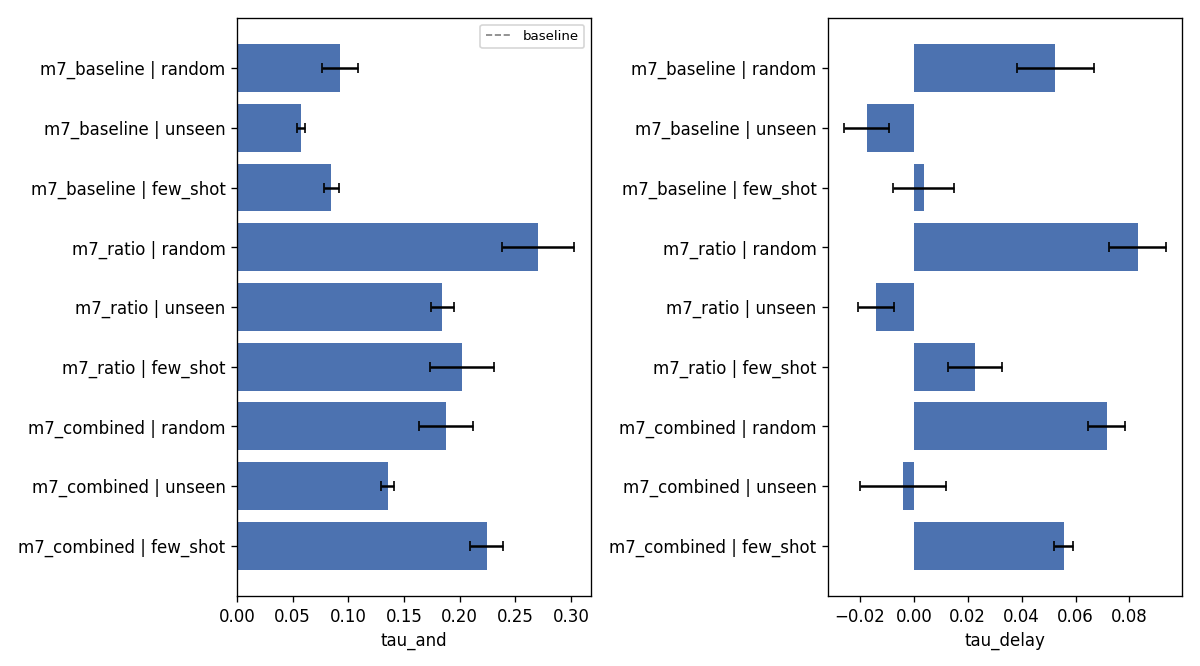

In [6]:
# Show the results (also stored inside this notebook when it is downloaded)
from IPython.display import Image, display
out = Path("/kaggle/working/results/generalisation")
print((out / "results_table.md").read_text())
print("===== results_table.csv =====")
print((out / "results_table.csv").read_text())
display(Image(str(out / "generalisation_bar.png")))
